In [30]:
import tensorflow as tf
import pandas as pd
import numpy as np
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import sklearn.datasets as datasets
from tensorflow import keras

from keras.models import Sequential
from keras import layers

import matplotlib.pyplot as pt

In [31]:
data =datasets.load_digits()

In [32]:
data.keys()

dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])

In [33]:
X= data['data']
y = data['target']

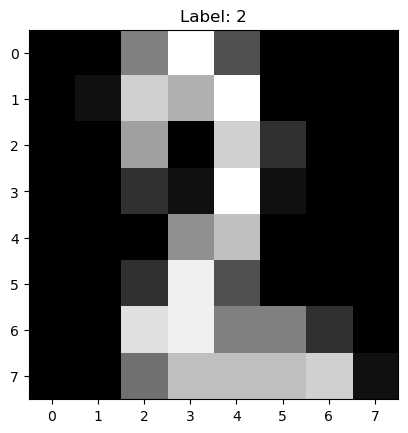

In [34]:
i = 22
pt.imshow(X[i].reshape(8,8), cmap='gray')
pt.title(f"Label: {y[i]}");

In [35]:
(x_train, x_test, y_train, y_test) = train_test_split(X, y, test_size=0.2, random_state=42)

In [36]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)


(1437, 64)
(1437,)
(360, 64)
(360,)


In [37]:
x_train = x_train.reshape(-1,8,8,1).astype('float32') / 255.0
x_test = x_test.reshape(-1,8,8,1).astype('float32') / 255.0


In [38]:
x_train[0].shape

(8, 8, 1)

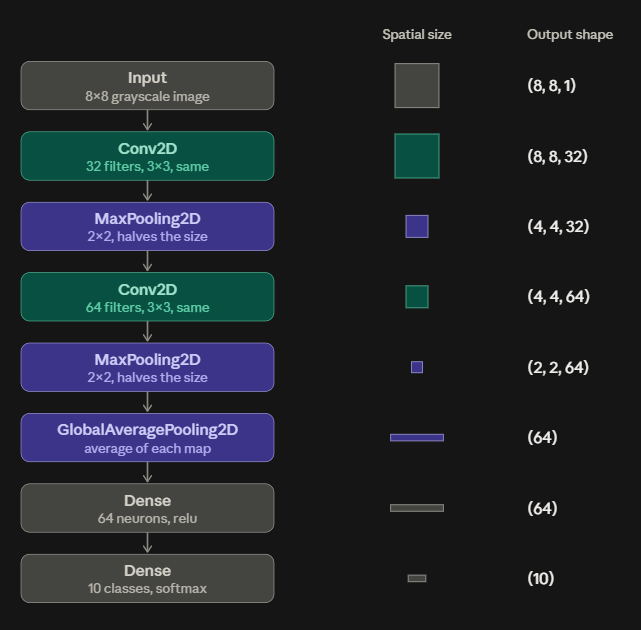

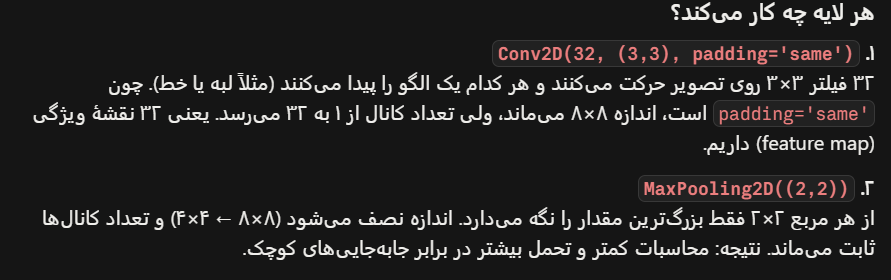

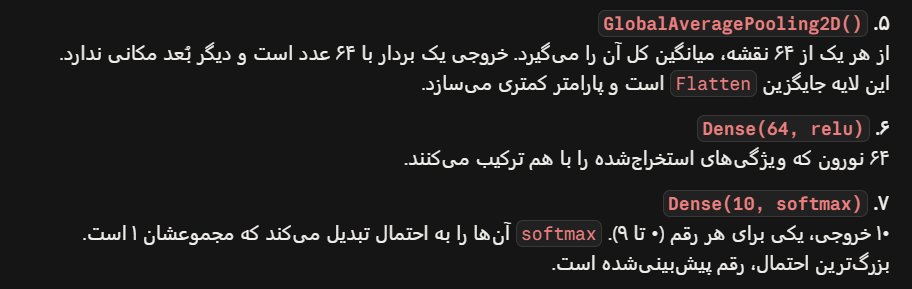

In [39]:
model = Sequential()
model.add(layers.Conv2D(32,(3,3), activation='relu', padding='same'))
model.add(layers.MaxPooling2D((2,2)))

model.add(layers.Conv2D(64,(3,3), activation='relu',padding='same'))
model.add(layers.MaxPooling2D((2,2)))

model.add(layers.GlobalAveragePooling2D()) # New
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10, activation='softmax'))

In [40]:
model_1 = Sequential(
    [
        layers.Conv2D(32, (6, 6), activation="relu", padding="Same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (6, 6), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)

In [41]:
# !pip install visualkeras

In [42]:
model_1.build(input_shape=(None, 28, 28, 1))

In [43]:
model_1.compile(optimizer='adam' , loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False) , metrics=['accuracy'])

In [44]:
model_1.fit(x_train, y_train, batch_size=50, epochs=32 , validation_split=0.1 , verbose= False)

In [45]:
model_1.evaluate(x_test,y_test)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9417 - loss: 0.1675 


[0.16748356819152832, 0.9416666626930237]

In [46]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',   
    metrics=['accuracy'],
)


In [ ]:
model.summary()

In [ ]:
model.fit(x_train, y_train, epochs=50, batch_size=32, validation_split=0.2)

In [ ]:
model.summary()

In [ ]:
model.evaluate(x_test,y_test)

In [ ]:
np.argmax(model.predict(x_test[1:2]))

In [ ]:
y_test[1:2]